# Phase A: Frage und Daten

Schritte 1 bis 5 aus `LERNPLAN.md`. Was wir dabei rausfinden, steht zusätzlich in `PROTOKOLL.md`, die Zusammenfassung in `docs/lernpfad.md`.

Bei der Begehung wurden sechs Arten von Befunden notiert. Wir schauen uns alle an.

## Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
METER_DIR = ROOT / "data" / "processed" / "real_meters"
BILDER = ROOT / "docs" / "assets" / "lernpfad"

## Schritt 2: Stationen anschauen

Bevor wir mit allen Stationen arbeiten, schauen wir uns erst mal einzelne HAST genauer an. Am besten solche, bei denen wir wissen, dass etwas kaputt war. Vielleicht sieht man dann, wie ein Fehler in den Daten aussieht.

Was bei den Begehungen gefunden wurde, steht in den Labels aus Notebook 27:

In [2]:
labels = pd.read_csv(ROOT / "data" / "processed" / "modell_labels.csv")
befunde = ["ventil", "daemmung", "filter", "durchfluss", "temperatur", "ueberdimensioniert"]
labels[befunde].sum()

ventil                11.0
daemmung              23.0
filter                26.0
durchfluss            20.0
temperatur            36.0
ueberdimensioniert     9.0
dtype: float64

| Befund | was bei der Begehung gemacht wurde |
|---|---|
| ventil | Stellventil oder Stellmotor getauscht, oder Ventilbefund im Freitext |
| daemmung | Leitungen gedämmt |
| filter | Filter gereinigt |
| durchfluss | Durchfluss neu eingestellt |
| temperatur | Rücklauf-Sollwert tagsüber gesenkt |
| ueberdimensioniert | Vertragsleistung verkleinert (nur bei 37 Stationen bekannt) |

Von jeder Befundart schauen wir uns eine Station an. Zuerst ausführlich das Ventil, danach die anderen fünf.

### Ventil

In [3]:
labels[labels["ventil"] == True].sort_values("erste_begehung")

,zaehler,begehungen,erste_begehung,strasse_gruppe,vertrag_alt_kw,vertrag_neu_kw,ventil,daemmung,filter,durchfluss,temperatur,ueberdimensioniert
7,68956351,1,2024-09-09,3,NaN,NaN,True,False,False,False,True,NaN
22,72135442,1,2024-09-12,4,NaN,10.0,True,False,False,True,True,NaN
10,68956355,1,2024-09-16,13,NaN,NaN,True,False,False,False,True,NaN
19,69527345,1,2024-09-17,4,10.0,10.0,True,True,True,False,True,0.0
45,80912182,1,2024-09-19,4,12.0,14.0,True,True,True,False,False,0.0
47,80912189,1,2024-09-19,3,NaN,NaN,True,True,True,True,False,NaN
29,80912154,1,2024-09-23,13,12.0,12.0,True,False,True,True,True,0.0
16,68956372,1,2024-10-14,7,8.0,6.0,True,True,True,True,False,1.0
21,72135441,1,2024-10-14,12,10.0,10.0,True,True,False,False,False,0.0
50,80912193,1,2024-11-05,12,10.0,10.0,True,False,False,False,True,0.0


11 Stationen hatten einen Ventilbefund. Wir nehmen die erste, Zähler 68956351. Dort war die Begehung am 09.09.2024, laut Protokoll wurde der Stellmotor getauscht.

In [4]:
df = pd.read_csv(METER_DIR / "68956351.csv", parse_dates=["Timestamp"])
print(len(df), "Zeilen")

32342 Zeilen


Erst mal Anfang und Ende der Tabelle anschauen:

In [5]:
df.head()

,Timestamp,Energy (kWh),Volume flow (l/h),Power (kW),Temperature difference (°C),Flow temperature (°C),Return temperature (°C),Volume (m³)
0,2021-11-01 23:00:00,17477.0,888.0,0.079,0.0,75.6,75.5,5865.545
1,2021-11-02 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2021-11-02 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2021-11-02 02:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2021-11-02 03:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
df.tail()

,Timestamp,Energy (kWh),Volume flow (l/h),Power (kW),Temperature difference (°C),Flow temperature (°C),Return temperature (°C),Volume (m³)
32337,2025-07-11 08:00:00,67414.0,0.0,0.000,8.4,65.2,56.8,24623.588
32338,2025-07-11 09:00:00,67414.0,0.0,0.000,2.7,57.6,54.8,24623.588
32339,2025-07-11 10:00:00,67414.0,0.0,0.000,-0.4,51.3,51.8,24623.588
32340,2025-07-11 11:00:00,67414.0,0.0,0.000,-1.6,46.4,48.0,24623.588
32341,2025-07-11 12:00:00,67416.0,378.0,4.963,11.5,75.8,64.3,24623.808


- Jede Zeile ist eine Stunde.
- Am Anfang fehlen viele Werte (NaN), das schauen wir uns in Schritt 3 an.
- `Energy` und `Volume` sind Zählerstände, die werden immer größer. Brauchen wir nicht.

Ein Wintertag, an dem alles gemessen wurde:

In [7]:
tag = df[(df["Timestamp"] >= "2024-01-15") & (df["Timestamp"] < "2024-01-16")]
tag

,Timestamp,Energy (kWh),Volume flow (l/h),Power (kW),Temperature difference (°C),Flow temperature (°C),Return temperature (°C),Volume (m³)
19297,2024-01-15 00:00:00,48096.0,486.0,3.887,7.0,72.5,65.4,20603.177
19298,2024-01-15 01:00:00,48099.0,476.0,1.607,2.9,74.1,71.1,20603.635
19299,2024-01-15 02:00:00,48104.0,480.0,5.489,10.0,73.6,63.6,20604.100
19300,2024-01-15 03:00:00,48107.0,525.0,2.241,3.7,74.5,70.8,20604.565
19301,2024-01-15 04:00:00,48110.0,500.0,6.440,11.2,74.3,63.0,20605.033
19302,2024-01-15 05:00:00,48114.0,446.0,2.042,4.0,73.1,69.1,20605.515
19303,2024-01-15 06:00:00,48117.0,274.0,5.126,16.3,70.9,54.6,20605.908
19304,2024-01-15 07:00:00,48122.0,256.0,4.442,15.1,73.2,58.1,20606.176
19305,2024-01-15 08:00:00,48127.0,225.0,3.521,13.6,71.2,57.6,20606.422
19306,2024-01-15 09:00:00,48132.0,256.0,4.550,15.5,72.3,56.8,20606.682


Der Vorlauf ist immer höher als der Rücklauf, weil die Station dem Wasser Wärme entzieht. Die Differenz ist die Spreizung.

Über die ganze Zeit:

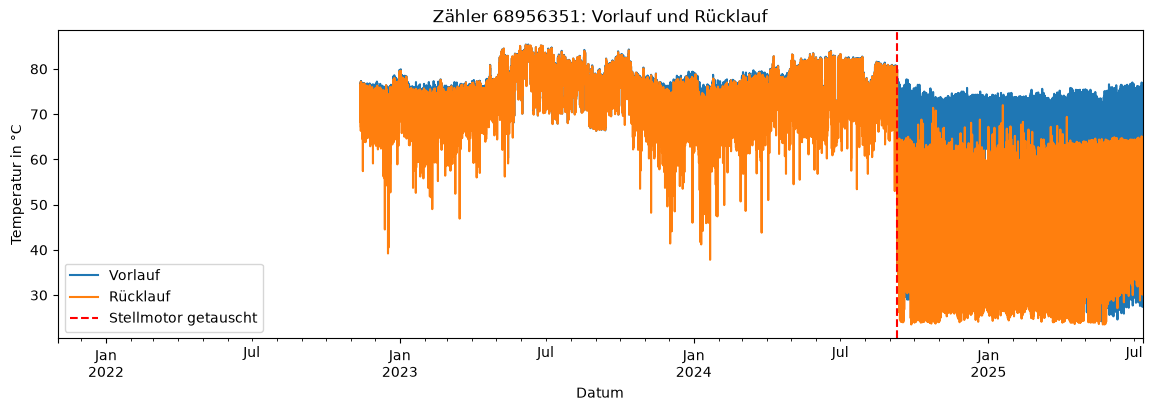

In [8]:
ax = df.plot(x = "Timestamp", y= ["Flow temperature (°C)", "Return temperature (°C)"], figsize= (14, 4))
ax.axvline(pd.Timestamp("2024-09-09"), color="red", linestyle="--")
ax.set_title("Zähler 68956351: Vorlauf und Rücklauf")
ax.set_xlabel("Datum")
ax.set_ylabel("Temperatur in °C")
ax.legend(["Vorlauf", "Rücklauf", "Stellmotor getauscht"])

In [9]:
ax.figure.savefig(BILDER / "02_vorlauf_ruecklauf.png", bbox_inches="tight")

Beim Tausch (rote Linie) fällt der Rücklauf von ca. 75 °C auf ca. 37 °C. Vorher war der Rücklauf fast so heiß wie der Vorlauf, das Wasser ist also einfach durchgelaufen.

Wie sieht der Durchfluss aus?

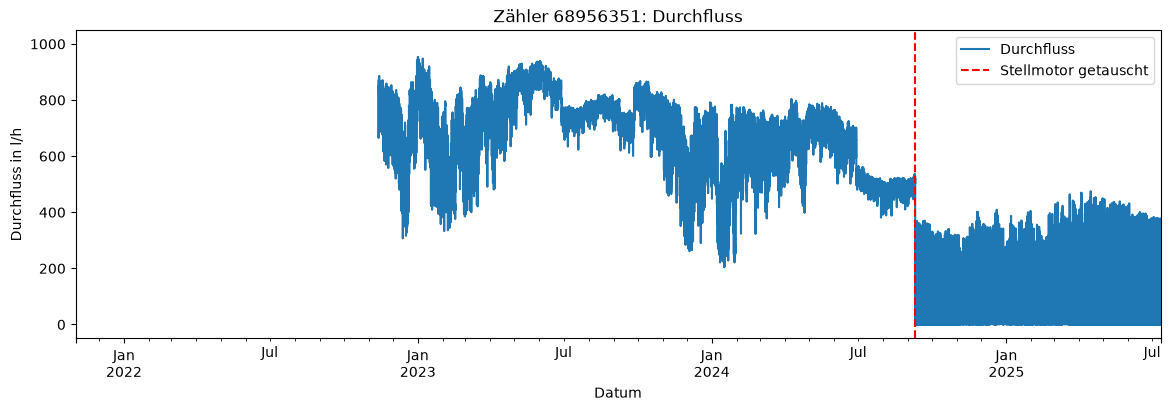

In [10]:
ax = df.plot(x= "Timestamp", y= "Volume flow (l/h)", figsize = (14, 4))
ax.axvline(pd.Timestamp("2024-09-09"), color="red", linestyle="--")
ax.set_title("Zähler 68956351: Durchfluss")
ax.set_xlabel("Datum")
ax.set_ylabel("Durchfluss in l/h")
ax.legend(["Durchfluss", "Stellmotor getauscht"])

In [11]:
ax.figure.savefig(BILDER / "02_durchfluss.png", bbox_inches="tight")

Nach dem Tausch fließt viel weniger Wasser (Januar 2024 ca. 480 l/h, Januar 2025 ca. 100 l/h). Wir dachten erst, bei kälterem Rücklauf muss mehr fließen, aber es ist umgekehrt: Wärme = Durchfluss mal Spreizung (ungefähr). Wenn das Wasser stärker abkühlt, reicht weniger Wasser.

Wichtig für später: Daten nach dem 09.09.2024 dürfen nicht ins Modell, sonst sieht es schon die reparierte Station (Leakage).

Komisch: Vor November 2022 ist in beiden Plots gar nichts zu sehen, obwohl die Daten schon 2021 anfangen. Das schauen wir uns in Schritt 3 an.

### Die anderen Befundarten

Für jede andere Befundart suchen wir eine Station, bei der möglichst nur dieser eine Befund notiert ist und das Datum der Begehung bekannt ist. Sonst weiß man nicht, welcher Befund was verursacht.

In [12]:
anzahl = labels[["ventil", "daemmung", "filter", "durchfluss", "temperatur"]].sum(axis=1)
mit_datum = labels["erste_begehung"].notna()

for b in befunde:
    kandidaten = labels[(labels[b] == 1) & (anzahl <= 1) & mit_datum]
    print(b, list(kandidaten["zaehler"]))

ventil []
daemmung [69527340, 80912163]
filter [68956352, 80912174]
durchfluss [80912173, 80912197]
temperatur [68956344, 69631918, 72167784, 80912162]
ueberdimensioniert [80912173, 80912197]


- Beim Ventil gibt es keine Station mit nur diesem Befund, deshalb oben die erste Ventilstation.
- Dämmung: 69527340, Filter: 68956352, Temperatur: 68956344, jeweils die erste in der Liste.
- Durchfluss und Überdimensionierung: Die beiden Stationen 80912173 und 80912197 haben beides. Wir nehmen 80912173 für die Überdimensionierung und 80912197 für den Durchfluss.

Die Begehungsdaten holen wir aus den Labels:

In [13]:
beispiele = {
    "daemmung": 69527340,
    "filter": 68956352,
    "durchfluss": 80912197,
    "temperatur": 68956344,
    "ueberdimensioniert": 80912173,
}

for b, z in beispiele.items():
    datum = labels[labels["zaehler"] == z]["erste_begehung"].iloc[0]
    print(b, z, datum)

daemmung 69527340 2024-11-19
filter 68956352 2024-09-18
durchfluss 80912197 2024-09-20
temperatur 68956344 2024-09-20
ueberdimensioniert 80912173 2024-09-10


Für jede Station Vorlauf und Rücklauf (links) und Durchfluss (rechts), die rote Linie ist die Begehung:

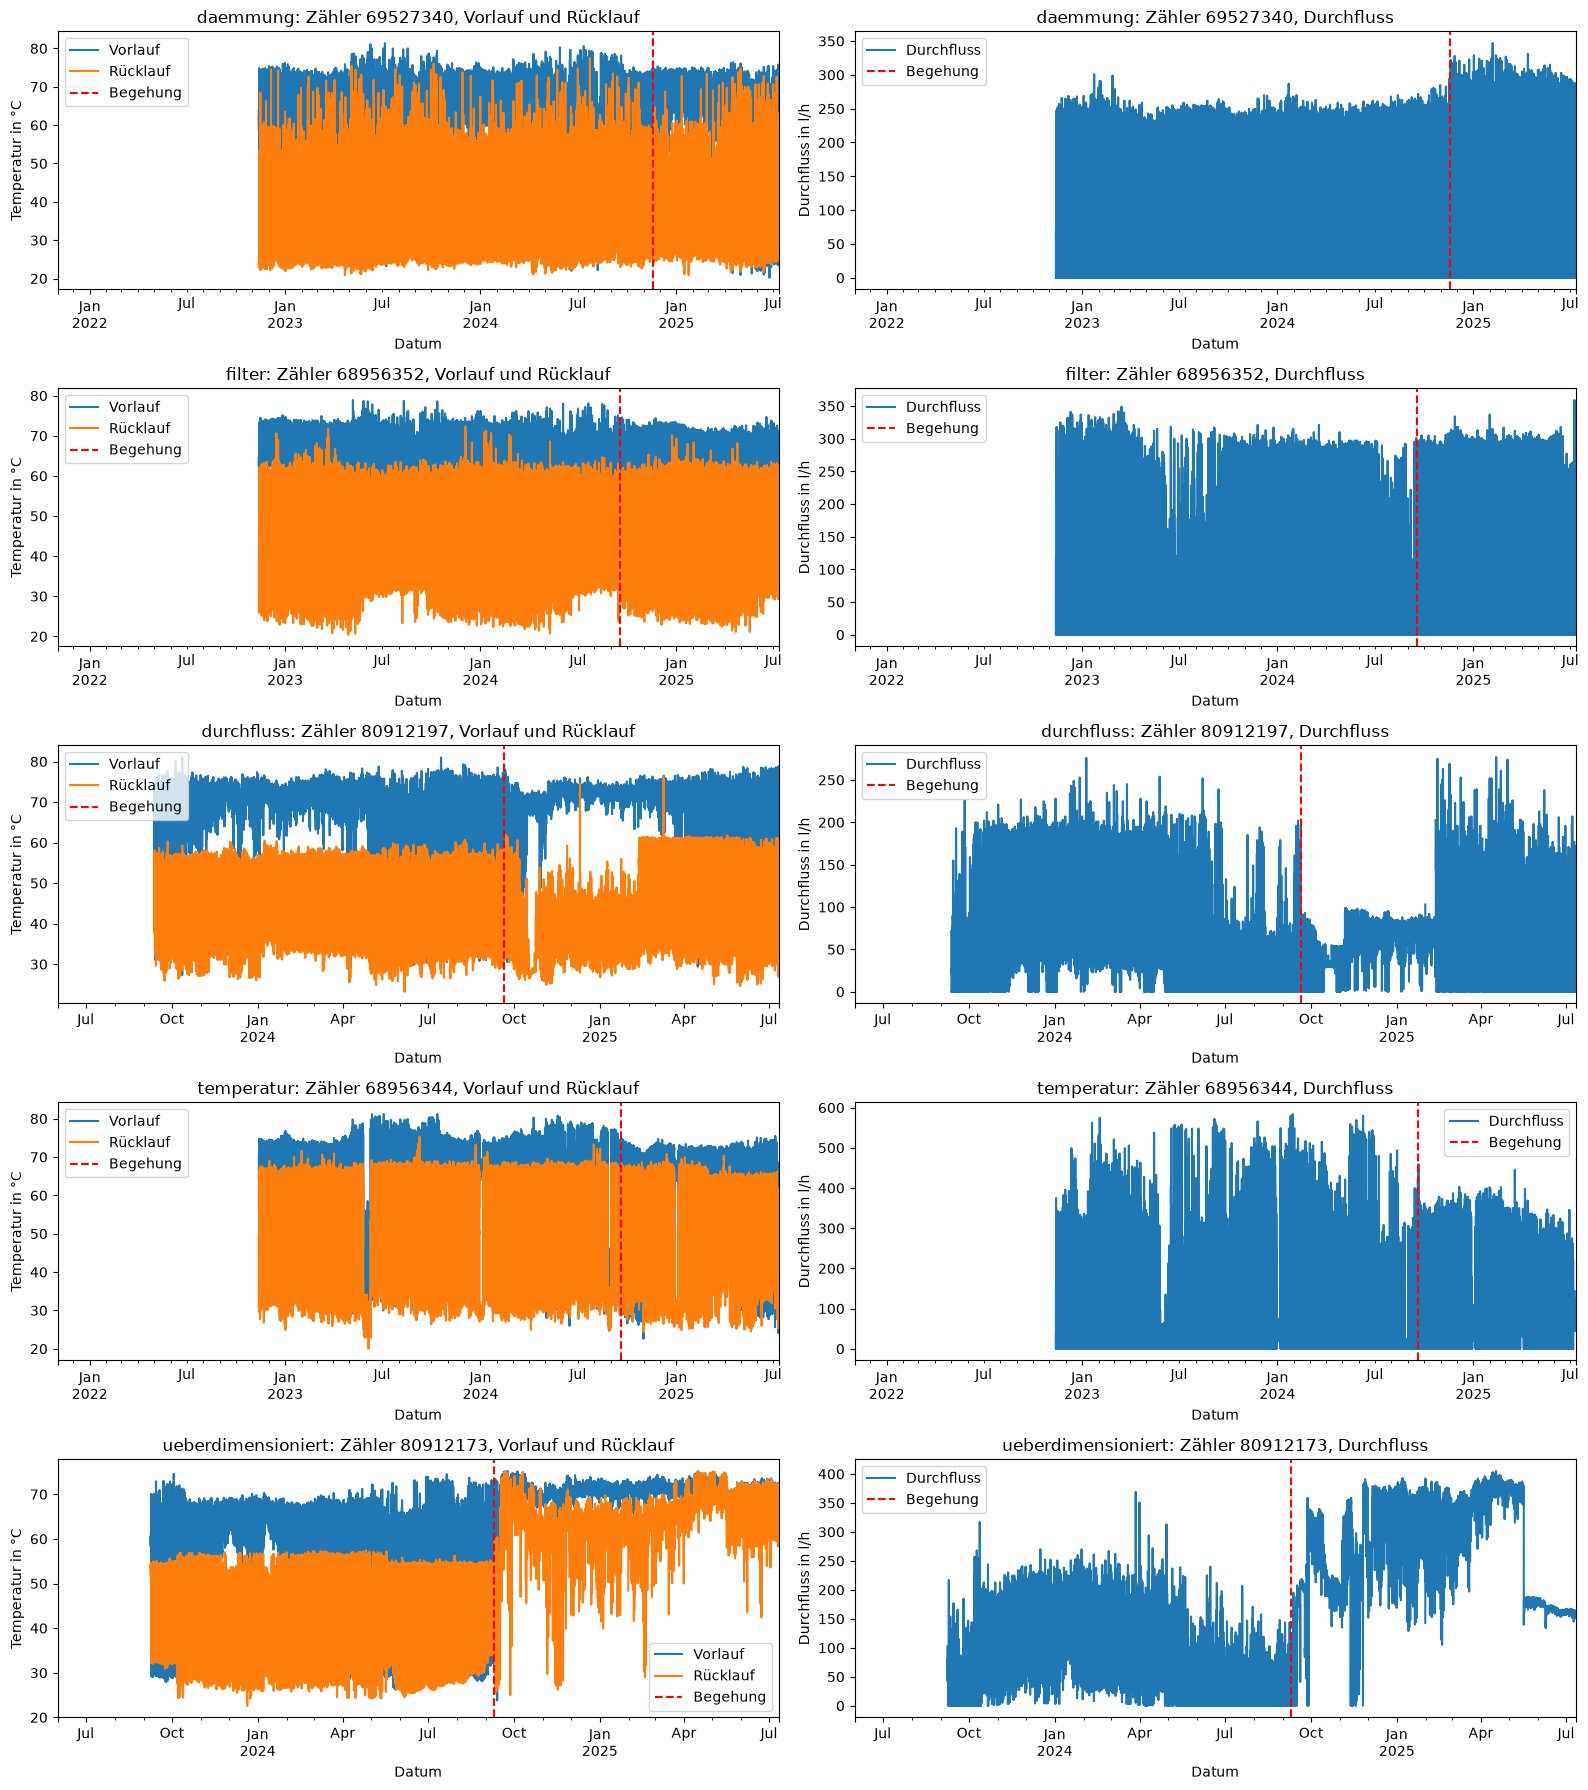

In [14]:
fig, axes = plt.subplots(5, 2, figsize=(16, 18))

for i, (b, z) in enumerate(beispiele.items()):
    d = pd.read_csv(METER_DIR / f"{z}.csv", parse_dates=["Timestamp"])
    datum = pd.Timestamp(labels[labels["zaehler"] == z]["erste_begehung"].iloc[0])

    ax = axes[i, 0]
    d.plot(x="Timestamp", y=["Flow temperature (°C)", "Return temperature (°C)"], ax=ax)
    ax.axvline(datum, color="red", linestyle="--")
    ax.set_title(f"{b}: Zähler {z}, Vorlauf und Rücklauf")
    ax.set_xlabel("Datum")
    ax.set_ylabel("Temperatur in °C")
    ax.legend(["Vorlauf", "Rücklauf", "Begehung"])

    ax = axes[i, 1]
    d.plot(x="Timestamp", y="Volume flow (l/h)", ax=ax)
    ax.axvline(datum, color="red", linestyle="--")
    ax.set_title(f"{b}: Zähler {z}, Durchfluss")
    ax.set_xlabel("Datum")
    ax.set_ylabel("Durchfluss in l/h")
    ax.legend(["Durchfluss", "Begehung"])

fig.tight_layout()

In [15]:
fig.savefig(BILDER / "02_beispiele_befunde.png", bbox_inches="tight")

- **Dämmung (69527340):** An der Begehung ändert sich nichts Sichtbares, weder bei den Temperaturen noch beim Durchfluss. Eine Dämmung im Keller hinterlässt in unseren Daten kaum eine Spur.
- **Filter (68956352):** Auch hier ändert sich auf den ersten Blick wenig.
- **Durchfluss (80912197):** Nach der Begehung sieht der Verlauf anders aus. Von Januar bis März 2025 läuft der Durchfluss fast konstant bei ca. 80 l/h, danach wieder normal. Was da los war, wissen wir nicht.
- **Temperatur (68956344):** In den Stundenwerten sieht man nichts. Der Sollwert wurde aber nur tagsüber gesenkt, das muss man sich über den Tag anschauen (unten).
- **Überdimensioniert (80912173):** Nach der Begehung laufen Durchfluss und Rücklauf deutlich höher als vorher. Der Vertrag wurde verkleinert, das ändert an der Station selbst nichts. Bei derselben Begehung wurde aber auch der Durchfluss neu eingestellt.

#### Temperatur: Rücklauf über den Tag

Median vom Rücklauf für jede Stunde des Tages, im Winter vor der Begehung (2023/24) und danach (2024/25):

In [16]:
d344 = pd.read_csv(METER_DIR / "68956344.csv", parse_dates=["Timestamp"])
winter_vor = d344[(d344["Timestamp"] >= "2023-10-01") & (d344["Timestamp"] < "2024-04-01")]
winter_nach = d344[(d344["Timestamp"] >= "2024-10-01") & (d344["Timestamp"] < "2025-04-01")]

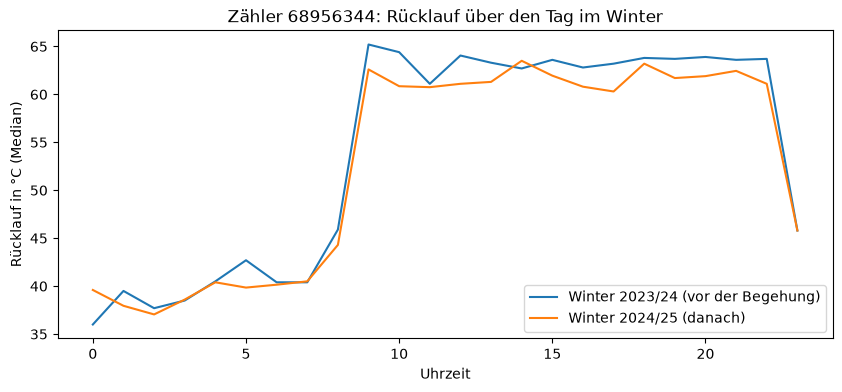

In [17]:
ax = winter_vor.groupby(winter_vor["Timestamp"].dt.hour)["Return temperature (°C)"].median().plot(figsize=(10, 4))
winter_nach.groupby(winter_nach["Timestamp"].dt.hour)["Return temperature (°C)"].median().plot(ax=ax)
ax.set_title("Zähler 68956344: Rücklauf über den Tag im Winter")
ax.set_xlabel("Uhrzeit")
ax.set_ylabel("Rücklauf in °C (Median)")
ax.legend(["Winter 2023/24 (vor der Begehung)", "Winter 2024/25 (danach)"])

In [18]:
ax.figure.savefig(BILDER / "02_temperatur_tagesprofil.png", bbox_inches="tight")

Tagsüber (ca. 9 bis 22 Uhr) liegt der Rücklauf danach etwa 1 bis 3 Grad niedriger, nachts ist er gleich. Die Änderung ist also da, aber klein.

#### Überdimensioniert: Leistung gegen Vertrag

Bei 80912173 wurde der Vertrag von 10 auf 8 kW verkleinert. Wie viel Leistung hat die Station vorher wirklich gebraucht?

In [19]:
d173 = pd.read_csv(METER_DIR / "80912173.csv", parse_dates=["Timestamp"])
winter173 = d173[(d173["Timestamp"] >= "2023-10-01") & (d173["Timestamp"] < "2024-04-01")]
winter173["Power (kW)"].quantile(0.99)

np.float64(6.748919999999996)

Selbst in den 1 % stärksten Stunden des Winters braucht sie nur ca. 6,7 kW, also zwei Drittel vom alten Vertrag. Das sieht man nur, wenn man die Leistung mit dem Vertrag vergleicht, nicht am Verlauf.

## Schritt 3: Datenqualität

Wie viel fehlt bei dieser Station?

In [20]:
df["Return temperature (°C)"].isna().mean()

np.float64(0.2677632799455816)

27 % der Stunden fehlen. Aber wo? Vorhandene Werte pro Jahr zählen (ein Jahr hat 8760 Stunden):

In [21]:
df.groupby(df["Timestamp"].dt.year)["Return temperature (°C)"].count()

Timestamp
2021      61
2022    1491
2023    8754
2024    8781
2025    4595
Name: Return temperature (°C), dtype: int64

2021 und 2022 haben sehr wenige Werte. 2021 sind es genau 61, so viele wie Tage im November und Dezember. Mal anschauen:

In [22]:
df[df["Timestamp"] < "2022-01-01"]

,Timestamp,Energy (kWh),Volume flow (l/h),Power (kW),Temperature difference (°C),Flow temperature (°C),Return temperature (°C),Volume (m³)
0,2021-11-01 23:00:00,17477.0,888.0,0.079,0.0,75.6,75.5,5865.545
1,2021-11-02 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2021-11-02 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2021-11-02 02:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2021-11-02 03:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
1436,2021-12-31 19:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1437,2021-12-31 20:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1438,2021-12-31 21:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1439,2021-12-31 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [23]:
df[df["Timestamp"] < "2022-01-01"].dropna()

,Timestamp,Energy (kWh),Volume flow (l/h),Power (kW),Temperature difference (°C),Flow temperature (°C),Return temperature (°C),Volume (m³)
0,2021-11-01 23:00:00,17477.0,888.0,0.079,0.0,75.6,75.5,5865.545
24,2021-11-02 23:00:00,17539.0,887.0,0.046,0.0,75.1,75.1,5885.251
48,2021-11-03 23:00:00,17606.0,885.0,0.104,0.1,75.8,75.7,5904.501
72,2021-11-04 23:00:00,17677.0,864.0,6.964,7.0,75.3,68.2,5923.281
96,2021-11-05 23:00:00,17747.0,858.0,0.167,0.1,73.2,73.0,5941.992
...,...,...,...,...,...,...,...,...
1344,2021-12-27 23:00:00,21978.0,803.0,0.435,0.4,73.9,73.4,6791.414
1368,2021-12-28 23:00:00,22052.0,857.0,0.079,0.0,74.9,74.9,6808.771
1392,2021-12-29 23:00:00,22129.0,877.0,0.090,0.1,74.9,74.8,6826.954
1416,2021-12-30 23:00:00,22184.0,847.0,0.256,0.2,75.2,74.9,6846.249


Alle Werte sind um 23 Uhr. Bis Ende Oktober 2022 gibt es also nur einen Wert pro Tag, erst danach Stundenwerte. Deshalb sieht man in den Plots davor nichts, einzelne Punkte werden nicht verbunden.

Auffüllen (Imputation) bringt hier nichts, weil 23 von 24 Stunden fehlen. Den Tagesverlauf müsste man erfinden. Nutzbar ist also November 2022 bis vor dem Tausch am 09.09.2024:

In [24]:
vorher = df[(df["Timestamp"] >= "2022-11-01") & (df["Timestamp"] < "2024-09-09")]
print(vorher.tail(30))

                Timestamp  Energy (kWh)  Volume flow (l/h)  Power (kW)  \
24979 2024-09-07 18:00:00       55316.0              510.0       0.073   
24980 2024-09-07 19:00:00       55316.0              505.0       0.078   
24981 2024-09-07 20:00:00       55317.0              502.0       6.799   
24982 2024-09-07 21:00:00       55319.0              490.0       0.103   
24983 2024-09-07 22:00:00       55319.0              484.0       0.037   
24984 2024-09-07 23:00:00       55319.0              521.0       0.126   
24985 2024-09-08 00:00:00       55319.0              528.0       0.098   
24986 2024-09-08 01:00:00       55319.0              516.0       0.045   
24987 2024-09-08 02:00:00       55321.0              523.0       0.145   
24988 2024-09-08 03:00:00       55322.0              527.0       0.046   
24989 2024-09-08 04:00:00       55322.0              499.0       0.031   
24990 2024-09-08 05:00:00       55322.0              492.0       0.084   
24991 2024-09-08 06:00:00       55322.

In [25]:
vorher["Return temperature (°C)"].isna().mean()

np.float64(0.017453294001966567)

Im Zeitraum fehlen nur noch ca. 2 %. Die Lücken lagen also fast alle in der Zeit mit Tageswerten.

Bisher war das aber nur eine Station. Ist das bei den anderen auch so?

In [26]:
fehlt = {}
for datei in METER_DIR.glob("*.csv"):
    d= pd.read_csv(datei, parse_dates=["Timestamp"])
    fehlt[datei.stem] = d["Return temperature (°C)"].isna().mean()

In [27]:
fehlt = pd.Series(fehlt).sort_values()
fehlt

81050517    0.083315
80912172    0.087222
81062289    0.091333
80912169    0.129327
80912189    0.129327
              ...   
72135480    0.504912
68956348    0.543875
68956359    0.544153
72135443    0.832115
72135441    0.832679
Length: 96, dtype: float64

In [28]:
fehlt.describe()

count    96.000000
mean      0.260680
std       0.134352
min       0.083315
25%       0.193102
50%       0.267701
75%       0.267987
max       0.832679
dtype: float64

Im Mittel fehlen 26 %, unsere Station ist mit 27 % also ganz normal. Am schlechtesten sind 72135443 und 72135441 mit 83 %.

In [29]:
# Die stationen mit den meisten fehlenden Daten : 1. 72135443	0.8321146008151522
#                                                 2. 72135441	0.832678994215842

72135441 hat Befunde beim Ventil und bei der Dämmung. Wie viel ist da noch übrig?

In [30]:
d441 = pd.read_csv(METER_DIR / "72135441.csv", parse_dates=["Timestamp"])

Text(0, 0.5, 'Temperatur in °C')

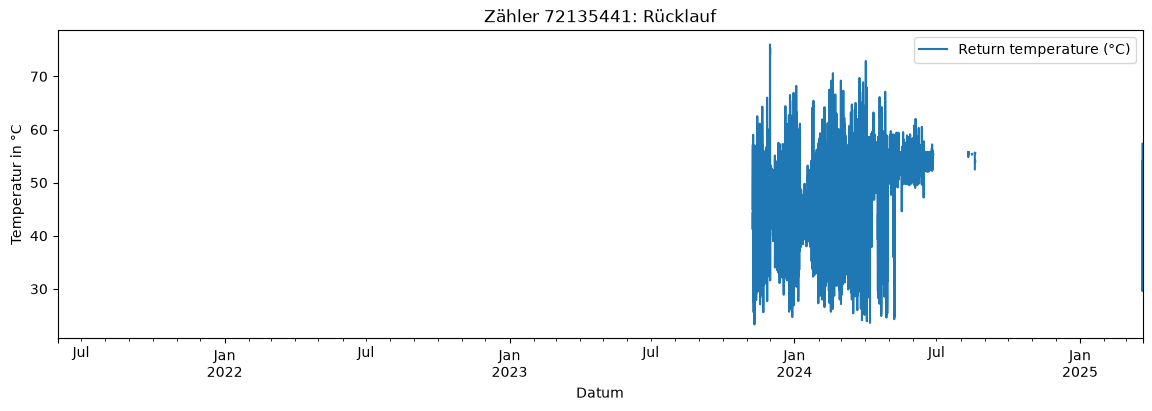

In [31]:
ax = d441.plot(x="Timestamp", y="Return temperature (°C)", figsize=(14, 4))
ax.set_title("Zähler 72135441: Rücklauf")
ax.set_xlabel("Datum")
ax.set_ylabel("Temperatur in °C")


Nur November 2023 bis Juni 2024, Juli und August 2024 fehlen. Bei nur 11 Ventilfällen ist das blöd, da zählt jede Station.

Wie sieht das bei allen Befundarten aus? Wie viele Fälle haben mehr als die Hälfte Lücken?

In [32]:
fehlt.index = fehlt.index.astype(int)
labels["fehlt"] = labels["zaehler"].map(fehlt)

for b in befunde:
    faelle = labels[labels[b] == 1]
    print(b, len(faelle), "Fälle, davon mit mehr als 50 % Lücken:", (faelle["fehlt"] > 0.5).sum())

ventil 11 Fälle, davon mit mehr als 50 % Lücken: 1
daemmung 23 Fälle, davon mit mehr als 50 % Lücken: 2
filter 26 Fälle, davon mit mehr als 50 % Lücken: 2
durchfluss 20 Fälle, davon mit mehr als 50 % Lücken: 1
temperatur 36 Fälle, davon mit mehr als 50 % Lücken: 1
ueberdimensioniert 9 Fälle, davon mit mehr als 50 % Lücken: 0


Bei jeder Befundart sind höchstens zwei Fälle betroffen, bei der Überdimensionierung keiner. Beim Ventil tut schon der eine weh, weil es nur 11 Fälle gibt.

### Sommernacht

Ein Ventil, das nicht schließt, sieht man am besten im Sommer nachts. Dann wird nicht geheizt und kaum Warmwasser gebraucht, eigentlich sollte fast nichts fließen. Median vom Durchfluss im Sommer 2024 zwischen 0 und 5 Uhr:

In [33]:
sommer = df[(df["Timestamp"] >= "2024-06-01") & (df["Timestamp"] < "2024-09-01")]
nacht = sommer[sommer["Timestamp"].dt.hour < 5]
nacht["Volume flow (l/h)"].median()

np.float64(520.5)

520 l/h. Ist das viel? Zum Vergleich brauchen wir eine Station ohne Befund. Alle Stationen, bei denen die Begehung nichts gefunden hat:

In [34]:
ohne = labels[labels[befunde].sum(axis=1) == 0]
ohne

,zaehler,begehungen,erste_begehung,strasse_gruppe,vertrag_alt_kw,vertrag_neu_kw,ventil,daemmung,filter,durchfluss,temperatur,ueberdimensioniert,fehlt
23,72135443,1,2024-12-02,2,14.0,14.0,False,False,False,False,False,0.0,0.832115
36,80912164,1,2024-08-26,4,10.0,10.0,False,False,False,False,False,0.0,0.129435
38,80912169,1,2024-11-19,12,11.0,11.0,False,False,False,False,False,0.0,0.129327
51,80912195,1,2024-09-11,1,NaN,NaN,False,False,False,False,False,NaN,0.208381
54,80912202,1,NaN,3,NaN,NaN,False,False,False,False,False,NaN,0.129381


72135443 hat 83 % Lücken, und bei 80912202 fehlt das Datum der Begehung (NaN heißt hier Datum fehlt, nicht keine Begehung). Wir nehmen 80912169. Dort war die Begehung erst im November 2024, der ganze Sommer liegt also davor.

In [35]:
d169 = pd.read_csv(METER_DIR / "80912169.csv", parse_dates=["Timestamp"])

In [36]:
sommer169 = d169[(d169["Timestamp"] >= "2024-06-01") & (d169["Timestamp"] < "2024-09-01")]
nacht169 = sommer169[sommer169["Timestamp"].dt.hour < 5]
nacht169["Volume flow (l/h)"].median()

np.float64(0.0)

0 l/h gegen 520 l/h. Als Bild:

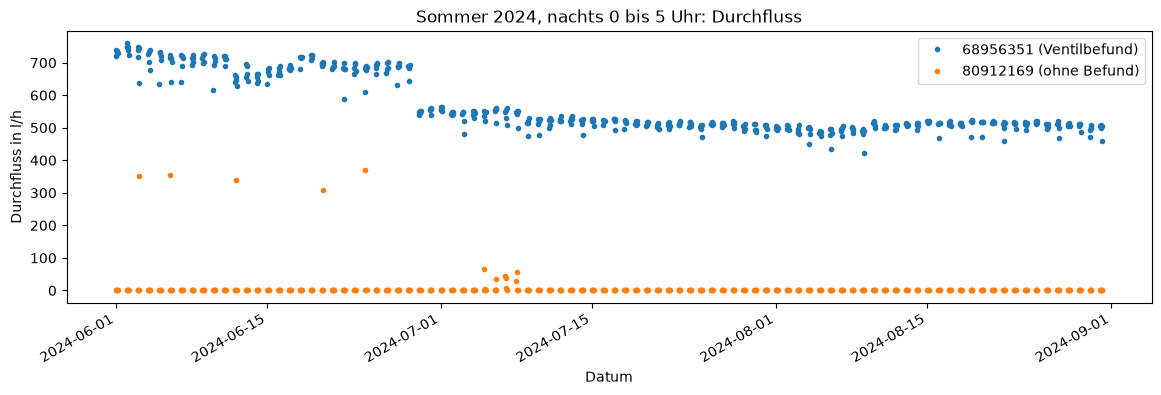

In [37]:
ax = nacht.plot(x="Timestamp", y="Volume flow (l/h)", style=".", figsize=(14, 4))
nacht169.plot(x="Timestamp", y="Volume flow (l/h)", style=".", ax=ax)
ax.set_title("Sommer 2024, nachts 0 bis 5 Uhr: Durchfluss")
ax.set_xlabel("Datum")
ax.set_ylabel("Durchfluss in l/h")
ax.legend(["68956351 (Ventilbefund)", "80912169 (ohne Befund)"])


In [38]:
ax.figure.savefig(BILDER / "03_sommernacht_vergleich.png", bbox_inches="tight")

Die gesunde Station hat nur ein paar einzelne Spitzen. Deshalb Median statt Mittelwert, den verschieben solche Ausreißer kaum.

Ist das bei allen 11 Ventilstationen so?

In [39]:
ventil = labels[labels["ventil"] == True]["zaehler"]
ventil

7     68956351
10    68956355
16    68956372
19    69527345
21    72135441
22    72135442
26    72167782
29    80912154
45    80912182
47    80912189
50    80912193
Name: zaehler, dtype: int64

In [40]:
nachtfluss = {}

for z in ventil:
    d= pd.read_csv(METER_DIR / f"{z}.csv", parse_dates=["Timestamp"])
    s= d[(d["Timestamp"] >= "2024-06-01") & (d["Timestamp"] < "2024-09-01")]
    n= s[s["Timestamp"].dt.hour < 5]
    nachtfluss[z] = n["Volume flow (l/h)"].median()

In [41]:
pd.Series(nachtfluss).sort_values()

80912193      0.0
80912189      0.0
72135442     30.0
72135441     45.5
69527345     56.5
68956355     67.0
68956372    359.0
80912154    494.5
68956351    520.5
80912182    551.0
72167782    753.0
dtype: float64

9 von 11 haben nachts Durchfluss, 5 davon über 300 l/h. Bei 2 sieht man gar nichts.

Gegenprobe mit den Stationen ohne Ventilbefund:

In [42]:
kein_ventil = labels[labels["ventil"] == False]["zaehler"]

In [43]:
nachtfluss_ohne = {}

for z in kein_ventil:
    d= pd.read_csv(METER_DIR / f"{z}.csv", parse_dates=["Timestamp"])
    s= d[(d["Timestamp"] >= "2024-06-01") & (d["Timestamp"] < "2024-09-01")]
    n= s[s["Timestamp"].dt.hour < 5]
    nachtfluss_ohne[z] = n["Volume flow (l/h)"].median()

In [44]:
pd.Series(nachtfluss_ohne).sort_values()

65273846      0.0
68956339      0.0
68956342      0.0
68956344      0.0
68956345      0.0
68956347      0.0
68956348      0.0
68956352      0.0
68956353      0.0
68956356      0.0
68956359      0.0
68956366      0.0
68956371      0.0
68956373      0.0
69527340      0.0
69631918      0.0
80912165      0.0
72135443      0.0
72135481      0.0
72135486      0.0
72167784      0.0
80912159      0.0
80912160      0.0
80912161      0.0
80912170      0.0
80912162      0.0
80912163      0.0
80912164      0.0
80912172      0.0
80912169      0.0
80912174      0.0
80912173      0.0
80912196      0.0
80912195      0.0
80912180      0.0
80912184      0.0
80912197      0.0
80912178     16.0
68956367     29.0
80912202     48.0
72167783     67.0
80912190    121.0
80912156      NaN
80912191      NaN
81019433      NaN
dtype: float64

Auch 5 Stationen ohne Ventilbefund haben nachts Durchfluss (16 bis 121 l/h, ganz unten in der Liste). Vielleicht wurde da bei der Begehung was übersehen.

Eine Regel "ab X l/h ist das Ventil kaputt" ist also immer ein Kompromiss:

- über 0 l/h: 9 von 11 gefunden, aber 5 Fehlalarme
- über 300 l/h: 0 Fehlalarme, aber nur 5 von 11 gefunden

Ist die Sommernacht nur fürs Ventil auffällig, oder auch für die anderen Befunde? Für jede Befundart: Anteil der Stationen mit Durchfluss nachts, mit und ohne Befund.

In [45]:
alle_nacht = {**nachtfluss, **nachtfluss_ohne}
labels["nachtfluss"] = labels["zaehler"].map(alle_nacht)

for b in befunde:
    mit = labels[labels[b] == 1].dropna(subset=["nachtfluss"])
    ohne = labels[labels[b] == 0].dropna(subset=["nachtfluss"])
    print(f"{b:20s} mit Befund: {(mit['nachtfluss'] > 0).mean():.0%}   ohne Befund: {(ohne['nachtfluss'] > 0).mean():.0%}")

ventil               mit Befund: 82%   ohne Befund: 12%
daemmung             mit Befund: 32%   ohne Befund: 23%
filter               mit Befund: 24%   ohne Befund: 29%
durchfluss           mit Befund: 22%   ohne Befund: 29%
temperatur           mit Befund: 30%   ohne Befund: 20%
ueberdimensioniert   mit Befund: 22%   ohne Befund: 19%


Nur beim Ventil ist der Unterschied groß. Bei den anderen Befunden läuft nachts mit und ohne Befund ungefähr gleich oft Wasser, die Sommernacht ist also ein Ventil-Merkmal. Für die anderen Befunde brauchen wir andere Kennzahlen (Phase B).

### Unmögliche Werte

Gibt es Werte, die es eigentlich nicht geben kann?

In [46]:
df.describe()

,Timestamp,Energy (kWh),Volume flow (l/h),Power (kW),Temperature difference (°C),Flow temperature (°C),Return temperature (°C),Volume (m³)
count,32342,23683.000000,23682.000000,23682.000000,23682.000000,23682.000000,23682.000000,23683.000000
mean,2023-09-06 17:30:00,50357.098763,490.483363,1.475772,7.275775,71.455582,64.143468,20463.561894
min,2021-11-01 23:00:00,17477.000000,0.000000,-6.043000,-17.000000,24.200000,23.500000,5865.545000
25%,2022-10-04 20:15:00,42699.000000,180.000000,0.047000,0.100000,69.800000,56.800000,17359.002000
50%,2023-09-06 17:30:00,51132.000000,595.000000,0.230000,1.000000,74.900000,72.100000,21301.326000
75%,2024-08-08 14:45:00,56972.000000,745.000000,2.056000,10.000000,77.200000,76.400000,24161.438500
max,2025-07-11 12:00:00,67416.000000,998.000000,30.517000,43.600000,85.400000,85.300000,24623.808000
std,NaN,10040.981371,309.669889,2.314490,11.691782,10.329262,17.889773,3903.258250


Die Spreizung geht bis -17 °C und die Leistung bis -6 kW. Das geht eigentlich nicht, der Rücklauf kann nicht wärmer sein als der Vorlauf. Wann passiert das?

In [47]:
df[df["Temperature difference (°C)"] < 0]["Volume flow (l/h)"].median()

np.float64(0.0)

Meistens fließt dann gar kein Wasser. Das Wasser steht im Rohr und die beiden Fühler kühlen unterschiedlich schnell ab, also ein Messeffekt. Die Spreizung werten wir später nur aus, wenn Wasser fließt.

## Schritt 4: Wetterdaten

Ein kalter Januar braucht mehr Wasser als ein warmer. War der Rückgang von 480 auf 100 l/h vielleicht nur das Wetter? Die Außentemperatur kommt von der DWD-Station Kitzingen, über `src/weather.py`:

In [48]:
sys.path.insert(0, str(ROOT))
from src.weather import load_outdoor_temperature

In [49]:
wetter = load_outdoor_temperature(df["Timestamp"].min(), df["Timestamp"].max())
wetter.head()

,timestamp,t_out,interpolated
0,2021-11-01 23:00:00,8.0,False
1,2021-11-02 00:00:00,7.2,False
2,2021-11-02 01:00:00,6.6,False
3,2021-11-02 02:00:00,5.1,False
4,2021-11-02 03:00:00,4.7,False


Mittlere Temperatur im Januar 2024 und im Januar 2025:

In [50]:
jan24 = wetter[(wetter["timestamp"] >= "2024-01-01") & (wetter["timestamp"] < "2024-02-01")]
jan24["t_out"].mean()

np.float64(1.4991935483870968)

In [51]:
jan25 = wetter[(wetter["timestamp"] >= "2025-01-01") & (wetter["timestamp"] < "2025-02-01")]
jan25["t_out"].mean()

np.float64(2.704704301075269)

Der Januar 2025 war nur gut ein Grad wärmer. Das erklärt nicht, dass nur noch ein Fünftel fließt.

Besser ist es, Tage mit gleicher Temperatur zu vergleichen. Dafür Station und Wetter zusammenlegen und Tageswerte bilden:

In [52]:
df2 = df.merge(wetter, left_on="Timestamp", right_on="timestamp")

In [53]:
tage = df2.resample("D", on="Timestamp").mean(numeric_only=True)
tage.head()

,Energy (kWh),Volume flow (l/h),Power (kW),Temperature difference (°C),Flow temperature (°C),Return temperature (°C),Volume (m³),t_out,interpolated
Timestamp,,,,,,,,,
2021-11-01,17477.0,888.0,0.079,0.0,75.6,75.5,5865.545,8.000000,0.0
2021-11-02,17539.0,887.0,0.046,0.0,75.1,75.1,5885.251,7.412500,0.0
2021-11-03,17606.0,885.0,0.104,0.1,75.8,75.7,5904.501,7.295833,0.0
2021-11-04,17677.0,864.0,6.964,7.0,75.3,68.2,5923.281,6.862500,0.0
2021-11-05,17747.0,858.0,0.167,0.1,73.2,73.0,5941.992,6.925000,0.0


Eine Zeile ist jetzt ein Tag, hinten ist `t_out` dazugekommen. Jetzt vor und nach dem Tausch trennen. `vor` fängt erst im November 2022 an, davor gibt es nur Tageswerte:

In [54]:
vor = tage[(tage.index >= "2022-11-01") & (tage.index < "2024-09-09")]
nach = tage[tage.index >= "2024-09-09"]

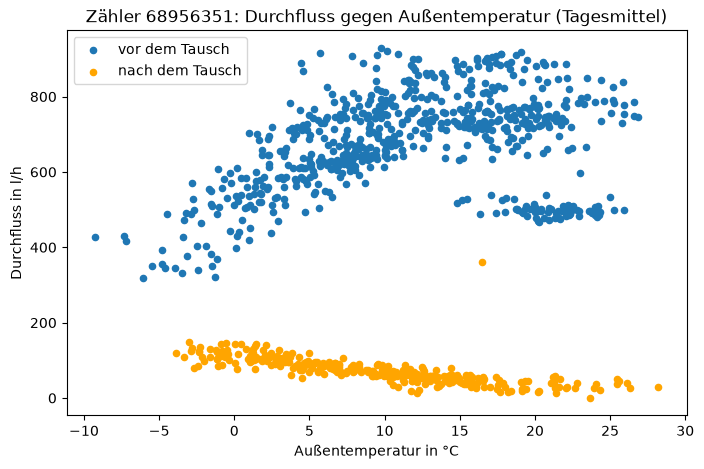

In [55]:
ax = vor.plot.scatter(x="t_out", y="Volume flow (l/h)", figsize=(8, 5))
nach.plot.scatter(x="t_out", y="Volume flow (l/h)", color="orange", ax=ax)
ax.set_title("Zähler 68956351: Durchfluss gegen Außentemperatur (Tagesmittel)")
ax.set_xlabel("Außentemperatur in °C")
ax.set_ylabel("Durchfluss in l/h")
ax.legend(["vor dem Tausch", "nach dem Tausch"])

In [56]:
ax.figure.savefig(BILDER / "04_durchfluss_aussentemperatur.png", bbox_inches="tight")

- Nach dem Tausch (orange): je kälter, desto mehr Wasser. So soll es sein.
- Vor dem Tausch (blau): genau umgekehrt, am meisten Wasser an warmen Tagen. Das Ventil hat nicht nach Bedarf geregelt.
- Bei Tagen um 0 °C: vorher ca. 530 l/h, nachher ca. 120 l/h. Am Wetter lag es also nicht.
- Ab ca. 15 °C wird die orange Wolke flach (Heizgrenze). Dann braucht die Station nur noch Warmwasser.

Dieselbe Kennlinie für die Beispielstationen der anderen Befundarten:

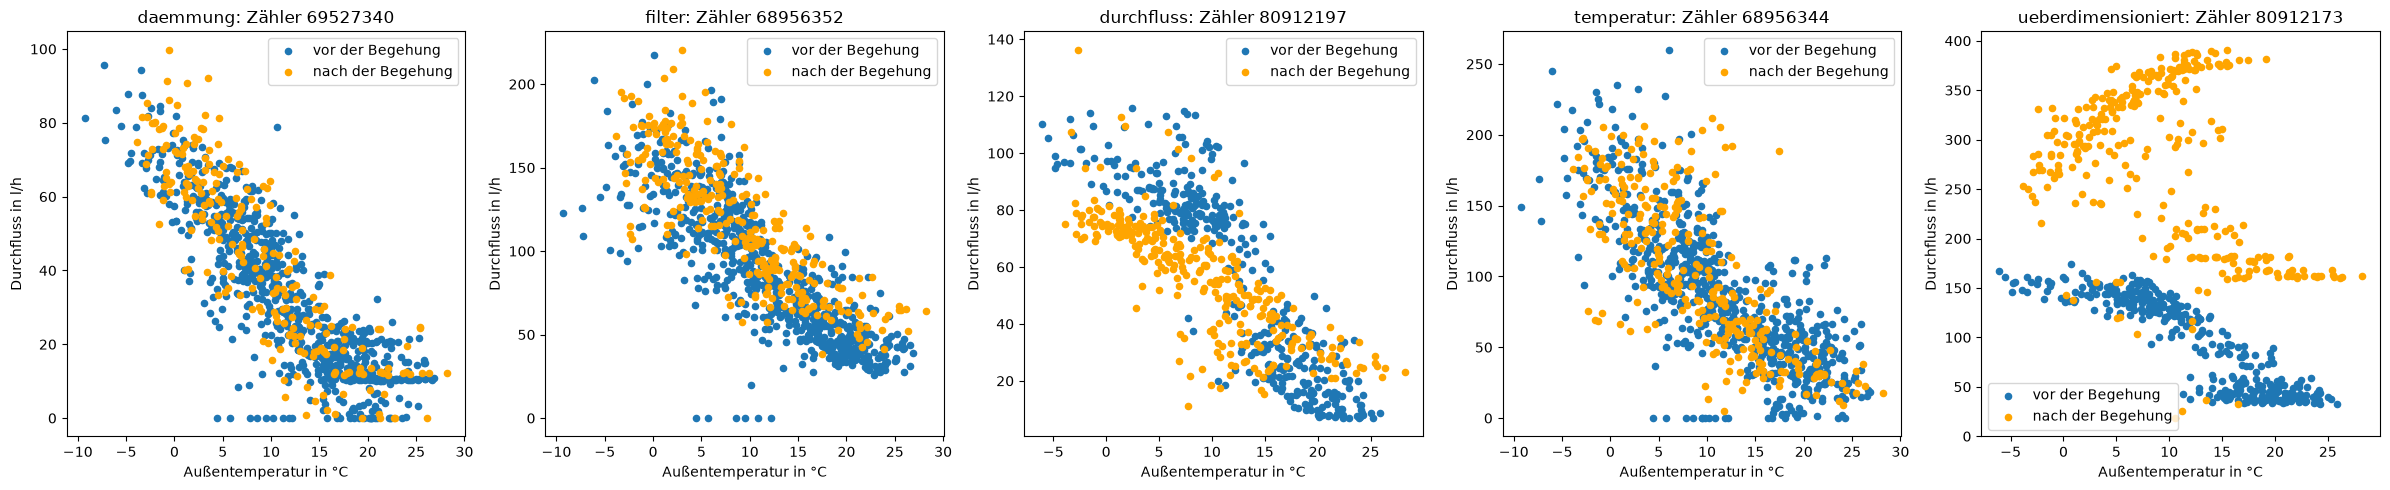

In [57]:
fig, axes = plt.subplots(1, 5, figsize=(24, 5))

for ax, (b, z) in zip(axes, beispiele.items()):
    d = pd.read_csv(METER_DIR / f"{z}.csv", parse_dates=["Timestamp"])
    datum = labels[labels["zaehler"] == z]["erste_begehung"].iloc[0]
    w = load_outdoor_temperature(d["Timestamp"].min(), d["Timestamp"].max())
    t = d.merge(w, left_on="Timestamp", right_on="timestamp").resample("D", on="Timestamp").mean(numeric_only=True)
    t_vor = t[(t.index >= "2022-11-01") & (t.index < datum)]
    t_nach = t[t.index >= datum]

    t_vor.plot.scatter(x="t_out", y="Volume flow (l/h)", ax=ax)
    t_nach.plot.scatter(x="t_out", y="Volume flow (l/h)", color="orange", ax=ax)
    ax.set_title(f"{b}: Zähler {z}")
    ax.set_xlabel("Außentemperatur in °C")
    ax.set_ylabel("Durchfluss in l/h")
    ax.legend(["vor der Begehung", "nach der Begehung"])

fig.tight_layout()

In [58]:
fig.savefig(BILDER / "04_kennlinien_befunde.png", bbox_inches="tight")

- **Dämmung:** vorher und nachher genau dieselbe Kennlinie.
- **Filter:** fast gleich, an kalten Tagen fließt nach dem Reinigen etwas mehr Wasser.
- **Durchfluss:** Nach dem Einstellen fließt bei mittleren Temperaturen (5 bis 12 °C) weniger Wasser.
- **Temperatur:** keine Änderung in den Tagesmitteln.
- **Überdimensioniert:** Nach der Begehung fließt viel mehr Wasser, und an warmen Tagen sogar mehr als an kalten, wie beim kaputten Ventil vorher. Da ist bei der Begehung wohl etwas schiefgegangen oder verstellt worden. Für die Überdimensionierung selbst sagt das nichts.

Nur beim Ventil und beim Durchfluss sieht man an der Kennlinie eine klare Änderung.

## Schritt 5: Begehungen

In [59]:
labels["erste_begehung"] = pd.to_datetime(labels["erste_begehung"])
labels["erste_begehung"].dt.to_period("M").value_counts().sort_index()

erste_begehung
2024-08     2
2024-09    32
2024-10     3
2024-11     9
2024-12     1
2025-03     1
2025-09     3
Freq: M, Name: count, dtype: int64

Die meisten Begehungen waren im September 2024 (32 von 51 mit Datum). Vor dem 01.09.2024 waren nur 2, beide im August. Bei 5 Stationen fehlt das Datum.

Deshalb gibt es einen gemeinsamen Stichtag, den 01.09.2024. Für die Diagnose nehmen wir nur Daten davor (bei den 2 aus dem August ihr eigenes Datum). So haben alle Stationen denselben Zeitraum und dasselbe Wetter und sind vergleichbar, auch die ohne Datum.

Viele Stationen haben mehrere Befunde auf einmal. Wie oft kommen zwei Befunde zusammen vor?

In [60]:
zusammen = pd.DataFrame(index=befunde, columns=befunde)
for a in befunde:
    for b in befunde:
        zusammen.loc[a, b] = ((labels[a] == 1) & (labels[b] == 1)).sum()
zusammen

,ventil,daemmung,filter,durchfluss,temperatur,ueberdimensioniert
ventil,11,6,5,5,7,1
daemmung,6,23,11,9,15,5
filter,5,11,26,10,18,4
durchfluss,5,9,10,20,13,8
temperatur,7,15,18,13,36,4
ueberdimensioniert,1,5,4,8,4,9


Auf der Diagonale steht, wie viele Fälle es von jedem Befund gibt. Zum Beispiel haben 6 der 11 Ventilstationen auch einen Dämmungsbefund und 5 einen Filterbefund. Temperatur ist mit 36 Fällen bei den meisten Stationen dabei, und 8 der 9 überdimensionierten Stationen hatten auch einen Durchfluss-Befund. Beim Verkleinern des Vertrags wurde der Durchfluss wohl gleich mit neu eingestellt. Wenn sich Befunde so überlappen, kann eine Kennzahl, die eigentlich zum Ventil gehört, auch bei der Dämmung oder dem Filter auffallen.